In [42]:
import numpy as np
data=np.loadtxt("./data.txt", delimiter='=', usecols=1)
n=int(data[0])
m=float(data[1])
a=float(data[2])
T_0=float(data[3])
R=float(data[4])
eps=float(data[5])
f=float(data[6])
L=float(data[7])
tau=float(data[8])
S0=int(data[9])
Sd=int(data[10])
Sout=int(data[11])
Sxyz=int(data[12])
N=n**3

In [43]:
r=np.empty((N,3))
p=np.empty((N,3))

In [44]:
b_0=np.array([a,0.,0.])
b_1=np.array([a/2., np.sqrt(3.)/2.*a,0.])
b_2=np.array([a/2., np.sqrt(3.)/6.*a, np.sqrt(2./3.)*a])
rng_i = np.arange(0,n,1)
i=[]
for i0 in rng_i:
    for i1 in rng_i:
        for i2 in rng_i:
            i_=i0+i1*n+i2*n**2           
            r[i_]=(i0-(n-1)/2)*b_0+(i1-(n-1)/2)*b_1+(i2-(n-1)/2)*b_2 
            i.append(i_)

In [45]:
r_sr=np.sum(r,axis=0)/N

In [46]:
file_initial=open('initial.xyz','w')
file_initial.write(f"{N}\n?\n")
for ll in range(N):
    file_initial.write(f"Ar {r[ll][0]} {r[ll][1]} {r[ll][2]} \n")
file_initial.close()

In [47]:
kb=8.31e-3
if T_0 == 0:
    p=np.zeros((N,3))
    Ekin_scaled=np.zeros((N,3))
else:
    lmb=1.0-np.random.rand(N,3)
    Ekin=-0.5*kb*T_0*np.log(lmb)
    E_sr_los=np.sum(Ekin)/3/N
    Ekin_scaled=Ekin*(0.5*kb*T_0/E_sr_los)
    s=np.random.choice([-1.0,1.0], size=(N,3))
    p=s*np.sqrt(2*m*Ekin_scaled)


In [48]:
P_tot=sum(p)
p_scaled=p-P_tot/N
np.savetxt('momenta.dat', p_scaled, delimiter='\t', header='px\tpy\tpz')

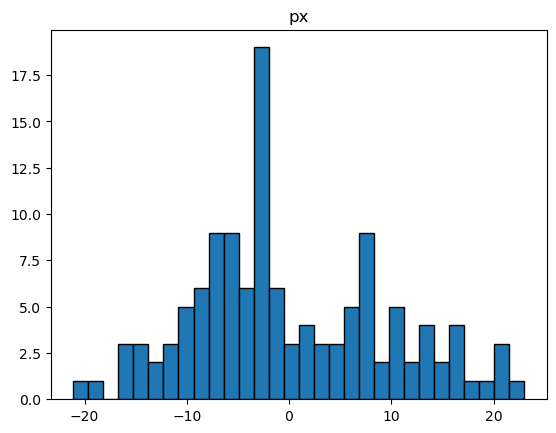

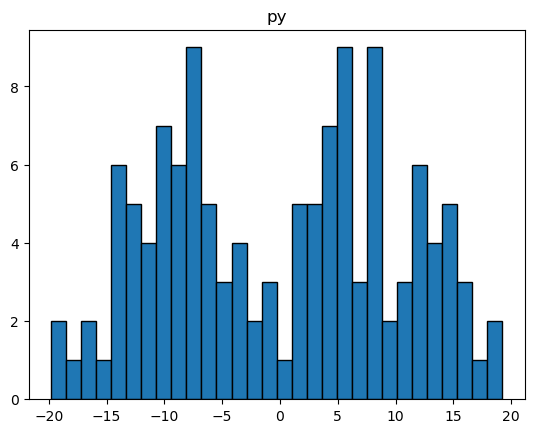

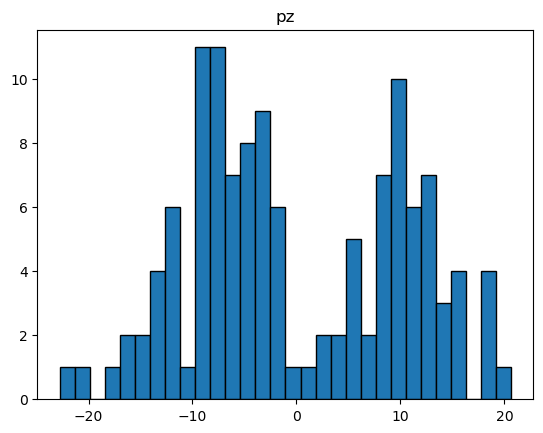

In [49]:
import matplotlib.pyplot as plt
px=p_scaled[:,0]
py=p_scaled[:,1]
pz=p_scaled[:,2]
plt.hist(px, bins=30, edgecolor='black')
plt.title('px')
plt.show()
plt.hist(py, bins=30, edgecolor='black')
plt.title('py')
plt.show()
plt.hist(pz, bins=30, edgecolor='black')
plt.title('pz')
plt.show()

In [50]:
suma_p_scaled=sum(p_scaled)

In [51]:
file_diagnostyka_1=open('diagnostyka1.txt','w')
file_diagnostyka_1.write(f'całkowita liczba atomów = {N}\n')
file_diagnostyka_1.write(f'wektor średniego przesunięcia r_x={r_sr[0]}, r_y={r_sr[1]}, r_z={r_sr[2]}\n')
file_diagnostyka_1.write(f'energia kinetyczna przed usunięciem ruchu środka masy = {1.5*N*kb*T_0}\n')
file_diagnostyka_1.write(f'suma pędów przed korektą {sum(p)}\n')
file_diagnostyka_1.write(f'suma pędów po korekcie {suma_p_scaled}\n')
file_diagnostyka_1.close()

In [53]:
F=np.zeros((N,3))
V=0
P=0

In [54]:
def oddzialywanie_atomy(r):
    V_p=[]
    F_out=np.zeros((N,3))
    for i in range(0,N):
        for j in range(0, i):
            r_diff_=r[i,:]-r[j,:]
            r_diff_val_=np.sqrt(np.sum(r_diff_**2))
            V_p_=eps*((R**12)/(r_diff_val_**12))-2*((R**6)/(r_diff_val_**6))
            V_p.append(V_p_)
            F_skalar=12 *eps* ((R**12 / r_diff_val_**13) - (R**6 / r_diff_val_**7))
            F_vec=F_skalar*(r_diff_/r_diff_val_)
            F_out[i]+=F_vec
            F_out[j]-=F_vec
    return V_p, F_out

In [55]:
def spherical(r):
    
    V_s_=np.empty(N)
    F_s_=np.empty((N,3))
    for i in range(0,N):
        r_i=np.sqrt(np.sum(r[i]**2))
        if r_i < L:
            F_s_[i]=np.zeros((1,3))
            V_s_[i]=0
        else:
            V_s_[i]=0.5*f*(r_i-L)**2
            F_s_[i]=f*(L-r_i)*r[i]/r_i
    return V_s_, F_s_

In [56]:
V_s0,F_s0=spherical(r)
V_p0,F_ij0=oddzialywanie_atomy(r)
V=sum(V_s0)+sum(V_p0)
print(V)
F=F_s0+F_ij0

-669.2932036253563


In [57]:
K=np.sum(np.sum(p_scaled**2)/2/m)
H=K+V

In [58]:
printcounterout=0
printcounterxyz=0
for s in range(0,S0+Sd-1):
    p_scaled=p_scaled+tau/2*F
    r=r+tau/m*p_scaled
    V_s_tau, F_s_tau=spherical(r)
    V_p_tau, F_ij_tau=oddzialywanie_atomy(r)
    V=sum(V_s_tau)+sum(V_p_tau)
    F=F_ij_tau+F_s_tau
    p_scaled=p_scaled+tau/2*F
    K=np.sum(np.sum(p_scaled**2)/2/m)
    H=K+V
    T=2/3/N/kb*K
    if printcounterout == Sout:
        file_out_1 = open("diagnostyka_dynamika.txt", "a")
        file_out_1.write(f's={s}, K={K}, H={H}, T={T}\n')
        file_out_1.close()
        printcounterout=0
    printcounterout+=1
    if printcounterxyz == Sxyz:
        file_out_xyz = open("sim.xyz", "a")
        file_out_xyz.write(f'{N}\n')
        file_out_xyz.write(f'frame t={printcounterxyz*tau} ps\n')
        for i in range(0,N):
            file_out_xyz.write(f'Ar {r[i,0]} {r[i,1]} {r[i,2]}\n')
        file_out_xyz.close()
        printcounterxyz=0
    printcounterxyz+=1
    



        
    
    